# 04. Model bazowy (baseline)

**Krok procesu:** 2. Model baseline (patrz `docs/proces_projektowy.png`).

Wybrana ścieżka: MediaPipe znajduje 21 punktów dłoni, nasz klasyfikator liczy z nich palce. Prowadzący potwierdził,
że taki pipeline spełnia wymagania kursu. Preprocessing i augmentacja działają więc na punktach dłoni, a xAI to SHAP.

Baseline to najprostsza sensowna wersja: sieć MLP 128-64 z domyślnymi parametrami na **surowych** współrzędnych
punktów (x, y znormalizowane do rozmiaru kadru, tak jak zwraca je MediaPipe). Bez żadnego naszego preprocessingu.
Jedyne skalowanie to `StandardScaler`, który jest częścią modelu, bo MLP bez niego trenuje się źle.

## Zasady oceny dla wszystkich kolejnych kroków

**Metryki jakości** (zawsze na zbiorze walidacyjnym, test zostaje na model końcowy):
- `val_macro_f1`: macro F1 na oficjalnym zbiorze val. Macro, bo klasy są niezbalansowane 8:1.
- `val_stress_macro_f1`: macro F1 na **teście obciążeniowym**. To ten sam zbiór val, ale każda dłoń jest losowo
  przechylona (do 45 stopni), rozciągnięta (proporcje kadru od 4:3 do 16:9), w połowie przypadków odbita lustrzanie
  i lekko zaszumiona. Symuluje telefon: inna kamera, inny kadr, lewa i prawa dłoń, drgania detektora.
  Kopia jest stała (ziarno 123), więc wszystkie modele dostają te same przykłady.

Test obciążeniowy jest potrzebny, bo na zwykłym val już eksploracja dała 0.99. Na samym val nie widać by różnicy
między krokami.

**Metryki GreenAI:** czas treningu, energia (kWh), emisja CO2 (g) z CodeCarbon, rozmiar modelu (KB), czas
predykcji jednej dłoni (ms).

**Szum:** każdy eksperyment trenujemy z 3 ziarnami losowymi i podajemy średnią oraz odchylenie standardowe.

**Bramka** (romb na diagramie, "czy wyniki i wskaźniki GreenAI się poprawiły?"). Nasza interpretacja:
1. Jakość: wzrost `val_stress_macro_f1` większy niż 2 odchylenia standardowe, bez spadku `val_macro_f1` poza szum.
2. GreenAI przy użyciu: rozmiar modelu i czas predykcji nie rosną. To koszt, który ponosi telefon przy każdej klatce.
3. GreenAI treningu: raportujemy zawsze. Wzrost energii treningu akceptujemy tylko przy realnym zysku jakości
   i opisujemy ten kompromis.

Jeśli bramka nie przechodzi, wracamy do poprzedniego modelu, tak jak każe diagram.

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import normalise
from labels import FINGER_JOINTS, HAND_EDGES
from pipeline import PREPROCESS, load_split, run_experiment, stress_set

FIG = Path("../reports/figures")
GATES = Path("../experiments/gates.json")
sns.set_theme(style="whitegrid")

lm_tr, y_tr, d_tr = load_split("train")
lm_va, y_va, d_va = load_split("val")
lm_st = stress_set(lm_va)
print(f"trening: {len(y_tr):,} dłoni, walidacja: {len(y_va):,} dłoni")

trening: 612,590 dłoni, walidacja: 76,669 dłoni


## Jak wygląda test obciążeniowy

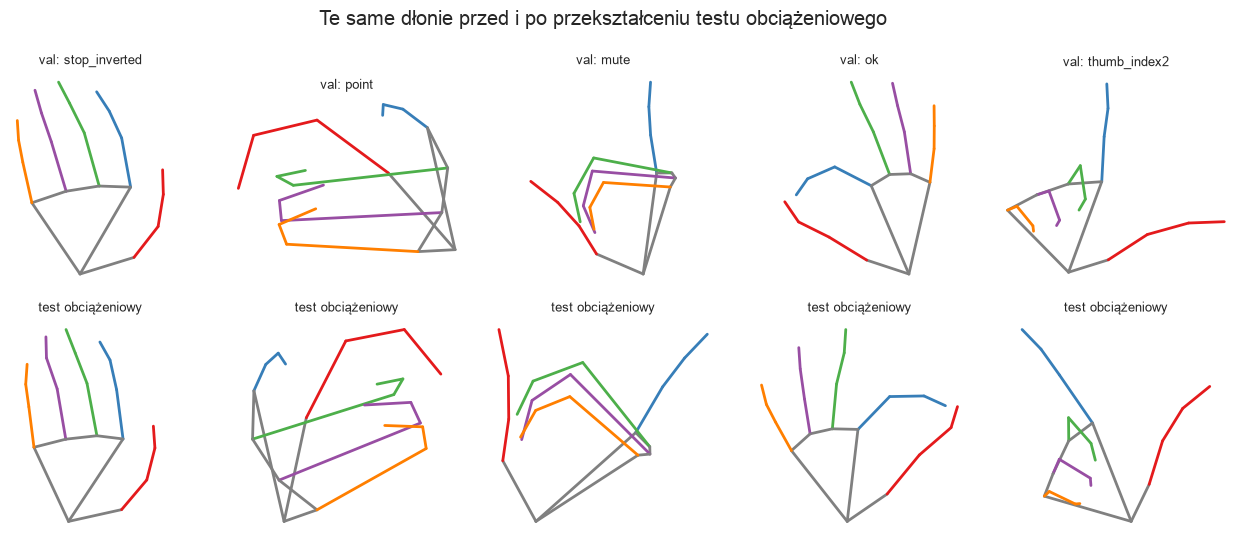

In [2]:
FINGER_COLOR = dict(zip(FINGER_JOINTS, sns.color_palette("Set1", 5)))
EDGE_FINGER = {e: next((f for f, j in FINGER_JOINTS.items() if set(e) <= set(j)), None) for e in HAND_EDGES}

def draw(ax, lm, title):
    lm = normalise(lm[None])[0]
    for e in HAND_EDGES:
        f = EDGE_FINGER[e]
        ax.plot(lm[list(e), 0], -lm[list(e), 1], lw=2, color=FINGER_COLOR[f] if f else "grey")
    ax.set_title(title, fontsize=9); ax.set_aspect("equal"); ax.axis("off")

idx = np.random.default_rng(0).choice(len(lm_va), 5, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for k, i in enumerate(idx):
    draw(axes[0, k], lm_va[i], f"val: {d_va.label[i]}")
    draw(axes[1, k], lm_st[i], "test obciążeniowy")
plt.suptitle("Te same dłonie przed i po przekształceniu testu obciążeniowego")
plt.tight_layout(); plt.savefig(FIG / "baseline_stress_examples.png", dpi=130); plt.show()

## B0: MLP 128-64 na surowych współrzędnych

In [3]:
def mlp_default(seed):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                         max_iter=50, random_state=seed))

prep = PREPROCESS["raw"]
b0, b0_runs = run_experiment("B0", "baseline", mlp_default, prep(lm_tr), y_tr, prep(lm_va), y_va, prep(lm_st),
                             notes={"model": "MLP 128-64, domyślne parametry", "notes": "surowe współrzędne x, y"},
                             gate="punkt odniesienia")
b0_runs.round(4)

[codecarbon INFO @ 17:04:51] offline tracker init


[codecarbon WARNING @ 17:04:51] Multiple instances of codecarbon are allowed to run at the same time.


,seed,val_macro_f1,val_stress_macro_f1,train_time_s,co2_g,energy_kwh
0,0,0.9915,0.8935,52.7394,0.1456,0.0002
1,1,0.9908,0.9051,49.9007,0.1349,0.0002
2,2,0.9910,0.9048,43.0569,0.1168,0.0002


In [4]:
pd.Series(b0).to_frame("B0")

,B0
experiment_id,B0
process_step,baseline
train_samples,612590
val_macro_f1,0.991111
val_macro_f1_std,0.000382
val_stress_macro_f1,0.901138
val_stress_macro_f1_std,0.0066
train_time_s,48.565655
energy_kwh,0.0002
co2_g,0.132415


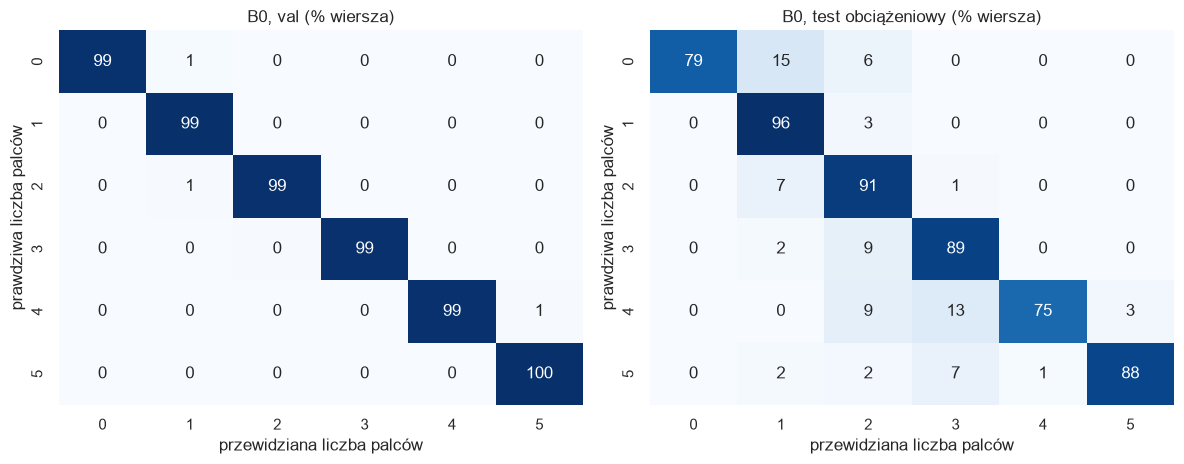

In [5]:
import pickle
model = pickle.load(open("../models/B0.pkl", "rb"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (X, name) in zip(axes, [(prep(lm_va), "val"), (prep(lm_st), "test obciążeniowy")]):
    cm = confusion_matrix(y_va, model.predict(X), normalize="true") * 100
    sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar=False)
    ax.set(xlabel="przewidziana liczba palców", ylabel="prawdziwa liczba palców", title=f"B0, {name} (% wiersza)")
plt.tight_layout(); plt.savefig(FIG / "baseline_confusion.png", dpi=150); plt.show()

In [6]:
# Zapisujemy tylko klucz baseline, wyniki kolejnych bramek zostają.
gates = json.loads(GATES.read_text()) if GATES.exists() else {}
gates["baseline"] = {"experiment_id": "B0", "preprocess": "raw", "augment": None,
                     "model": {"hidden_layer_sizes": [128, 64]}}
GATES.write_text(json.dumps(gates, indent=2, ensure_ascii=False))

179

## Wnioski

- **Na zwykłym val baseline jest już bardzo dobry: macro F1 0.9911 (±0.0004).** Dane HaGRID to pozowane gesty
  z kamery z przodu, więc surowe współrzędne wystarczają, jeśli dłoń wygląda tak jak w treningu.
- **Na teście obciążeniowym spada do 0.901 (±0.007).** Wystarczy przechylić dłoń, zmienić proporcje kadru albo
  odbić obraz. Najgorzej wypada 4 palce (75%, mylone z 3 i 2) i 0 palców (79%, mylone z 1). To jest główny problem
  do rozwiązania w kolejnych krokach, bo telefon da właśnie takie dane.
- **Odchylenie między ziarnami jest 17 razy większe na teście obciążeniowym niż na val.** Dlatego bramki liczą próg
  z odchylenia, a nie ze stałej.
- **GreenAI:** trening 49 s, 0.20 Wh, 0.13 g CO2 (około 1 m jazdy samochodem). Model 175 KB, 0.14 ms na dłoń.
  Koszt predykcji jest pomijalny przy 30 klatkach na sekundę.

**Do kroku preprocessingu idzie B0.** Które przekształcenie szkodzi najbardziej, sprawdzamy w `05_preprocessing.ipynb`.